# Analises dos dados e graficos

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
df = pd.read_csv('history_traduzido.csv')

In [15]:
tipos_colunas = {
    'tempo_permanencia': 'int64',
    'cobranca_mensal': 'float64',
    'cobranca_total_acumulada': 'float64',
    'renda_mensal': 'float64',
    'id_cliente': 'string',
    'feedback_cliente': 'string',
    'idoso': 'category',
    'genero': 'category',
    'possui_companheiro': 'category',
    'possui_dependentes': 'category',
    'servico_telefonico': 'category',
    'multiplas_linhas_telefonicas': 'category',
    'servico_internet': 'category',
    'seguranca_online': 'category',
    'backup_online': 'category',
    'protecao_dispositivos': 'category',
    'suporte_tecnico': 'category',
    'streaming_tv': 'category',
    'streaming_filmes': 'category',
    'tipo_contrato': 'category',
    'faturamento_digital': 'category',
    'metodo_pagamento': 'category',
    'cancelamento_servico': 'category'
}

colunas_float = ['cobranca_mensal', 'cobranca_total_acumulada', 'renda_mensal']
colunas_int = ['idoso', 'tempo_permanencia']

for col in colunas_float + colunas_int:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')
        
df['idoso'] = df['idoso'].fillna(0)
df['tempo_permanencia'] = df['tempo_permanencia'].fillna(0)

df = df.astype(tipos_colunas)

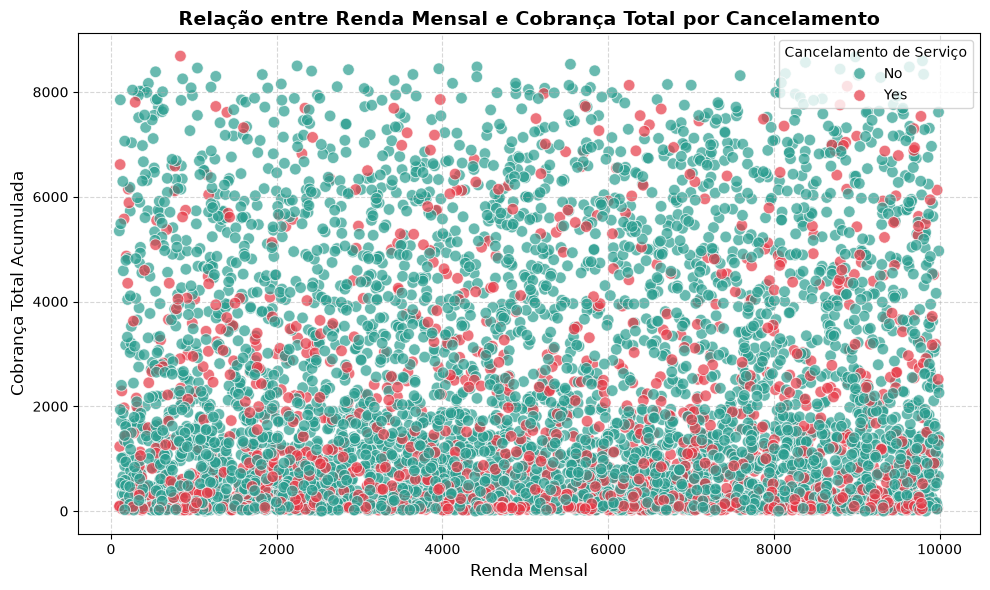

In [4]:
# Definir o tamanho do gráfico
plt.figure(figsize=(10, 6))

# Criar o gráfico de dispersão
sns.scatterplot(
    data=df,
    x='renda_mensal',
    y='cobranca_total_acumulada',
    hue='cancelamento_servico',
    palette={'Yes': '#E63946', 'No': '#2A9D8F'},  # Vermelho para 'Yes' e Verde/Azul para 'No'
    alpha=0.7,
    s=70  # Tamanho dos pontos
)

# Formatação visual
plt.title('Relação entre Renda Mensal e Cobrança Total por Cancelamento', fontsize=14, fontweight='bold')
plt.xlabel('Renda Mensal', fontsize=12)
plt.ylabel('Cobrança Total Acumulada', fontsize=12)
plt.legend(title='Cancelamento de Serviço')
plt.grid(True, linestyle='--', alpha=0.5)

# Exibir o gráfico
plt.tight_layout()
plt.show()

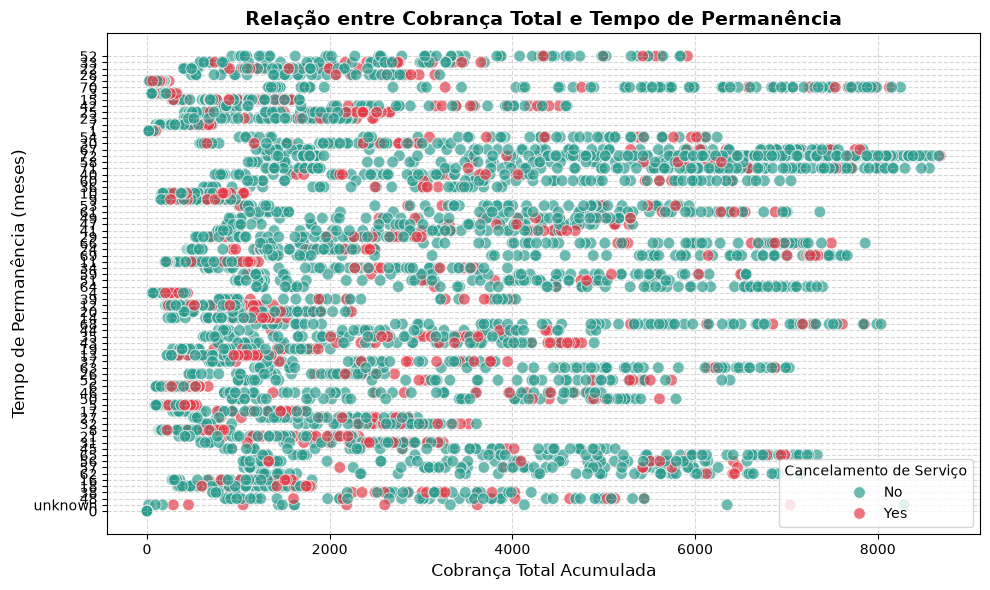

In [5]:
plt.figure(figsize=(10, 6))

# Criar o gráfico de dispersão com tempo_permanencia no eixo Y
sns.scatterplot(
    data=df,
    x='cobranca_total_acumulada',
    y='tempo_permanencia',
    hue='cancelamento_servico',
    palette={'Yes': '#E63946', 'No': '#2A9D8F'}, # Vermelho para 'Yes', Verde/Azul para 'No'
    alpha=0.7,
    s=70
)

# Personalização dos eixos e títulos
plt.title('Relação entre Cobrança Total e Tempo de Permanência', fontsize=14, fontweight='bold')
plt.xlabel('Cobrança Total Acumulada', fontsize=12)
plt.ylabel('Tempo de Permanência (meses)', fontsize=12)
plt.legend(title='Cancelamento de Serviço')
plt.grid(True, linestyle='--', alpha=0.5)

# Exibir o gráfico
plt.tight_layout()
plt.show()

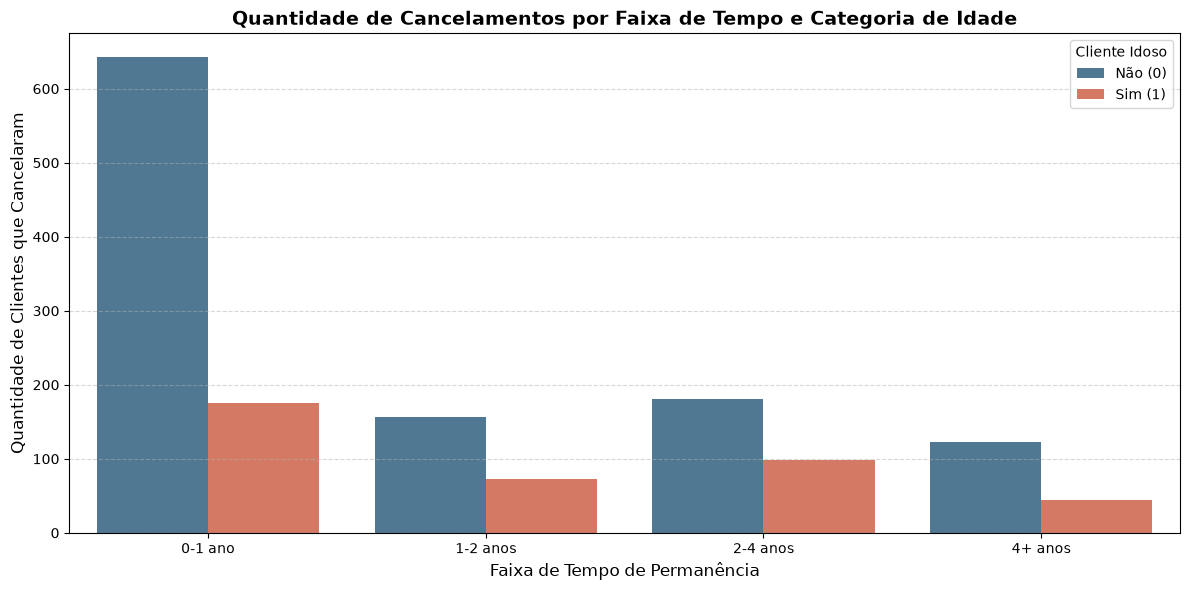

In [ ]:
# Converter a coluna para formato numérico (força conversão e ignora espaços em branco)
df['tempo_permanencia'] = pd.to_numeric(df['tempo_permanencia'], errors='coerce')

# Criar as faixas de tempo
df['faixa_permanencia'] = pd.cut(
    df['tempo_permanencia'], 
    bins=[0, 12, 24, 48, 100], 
    labels=['0-1 ano', '1-2 anos', '2-4 anos', '4+ anos'],
    include_lowest=True
)

# Gerar o gráfico
plt.figure(figsize=(12, 6))

df_cancelados = df[df['cancelamento_servico'] == 'Yes']

sns.countplot(
    data=df_cancelados,
    x='faixa_permanencia',
    hue='idoso',
    palette={0: '#457B9D', 1: '#E76F51'}
)

plt.title('Quantidade de Cancelamentos por Faixa de Tempo e Categoria de Idade', fontsize=14, fontweight='bold')
plt.xlabel('Faixa de Tempo de Permanência', fontsize=12)
plt.ylabel('Quantidade de Clientes que Cancelaram', fontsize=12)
plt.legend(title='Cliente Idoso', labels=['Não (0)', 'Sim (1)'])
plt.grid(True, axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

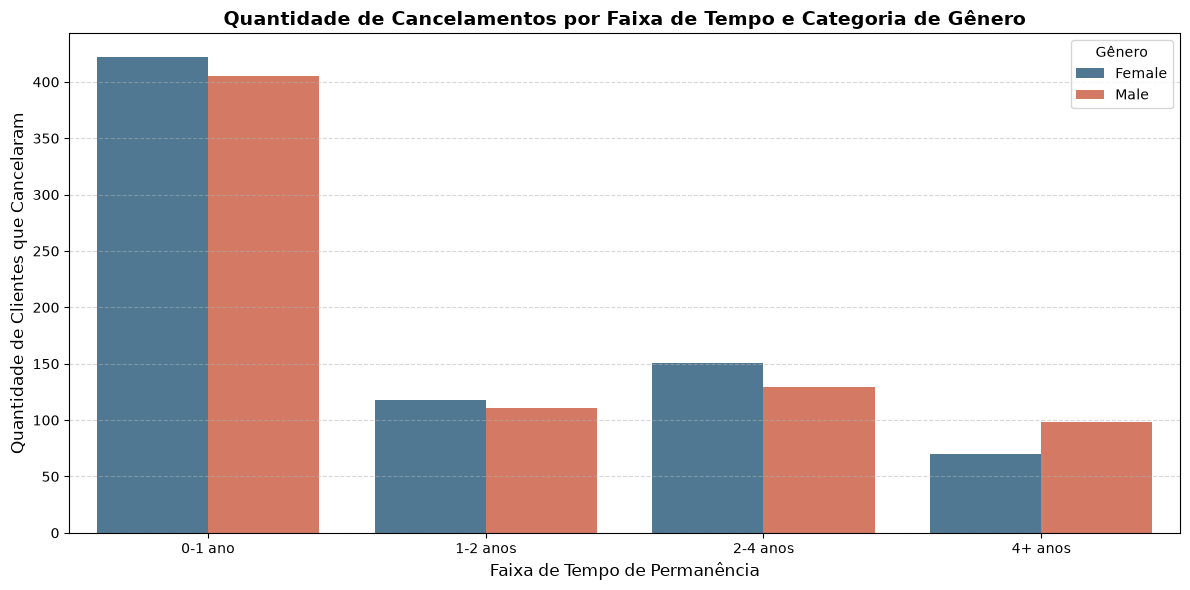

In [17]:
df['tempo_permanencia'] = pd.to_numeric(df['tempo_permanencia'], errors='coerce')

df['faixa_permanencia'] = pd.cut(
    df['tempo_permanencia'], 
    bins=[0, 12, 24, 48, 100], 
    labels=['0-1 ano', '1-2 anos', '2-4 anos', '4+ anos'],
    include_lowest=True
)

plt.figure(figsize=(12, 6))

df_cancelados = df[df['cancelamento_servico'] == 'Yes']

sns.countplot(
    data=df_cancelados,
    x='faixa_permanencia',
    hue='genero',
    palette=['#457B9D', '#E76F51']  # Passando como lista, o Seaborn atribui as cores automaticamente
)

plt.title('Quantidade de Cancelamentos por Faixa de Tempo e Categoria de Gênero', fontsize=14, fontweight='bold')
plt.xlabel('Faixa de Tempo de Permanência', fontsize=12)
plt.ylabel('Quantidade de Clientes que Cancelaram', fontsize=12)
plt.legend(title='Gênero')
plt.grid(True, axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()